# Synthetic spectra generation

Generate M-dwarf synthetic spectra in the **8800 - 8835 $\AA$** window with Korg, save them to `data/*.parquet`, and inspect the parameter distributions.

## Setup

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(REPO_ROOT))

from src.datagen import install_korg

install_korg()

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import src.datavis as datavis
from src.datagen import generate_synthetic_spectra_dataset

M-dwarf physical ranges. Teff range source: https://www.pas.rochester.edu/~emamajek/EEM_dwarf_UBVIJHK_colors_Teff.txt

In [ ]:
EFFECTIVE_TEMP_RANGE_K = (2350.0, 3850.0)  # Teff in Kelvin
METALLICITY_FEH_RANGE = (-0.5, 0.5)  # [Fe/H] in dex
MASS_RANGE_MSUN = (0.079, 0.57)  # stellar mass in M_sun, M0 V to M7 V
WAVELENGTH_WINDOW_A = (8800.0, 8835.0)  # baseline spectral window

NUM_SAMPLES = 5_000

## Generate data

In [4]:
data = generate_synthetic_spectra_dataset(
    num_samples=NUM_SAMPLES,
    teff_range_K=EFFECTIVE_TEMP_RANGE_K,
    feh_range_dex=METALLICITY_FEH_RANGE,
    mass_range_msun=MASS_RANGE_MSUN,
    wavelength_window_A=WAVELENGTH_WINDOW_A,
)

df_spectra = pd.DataFrame(data)
df_spectra.head()

Synthesizing spectra...:   0%|          | 0/5000 [00:00<?, ?sample/s]

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3129.031349,4.903465,-0.398154,0.317017,0.329086,"[8800.0, 8800.01, 8800.02, 8800.03, 8800.04, 8...","[0.9995366394397178, 0.9995358624549017, 0.999...","[554887.0759011065, 554887.0090868353, 554886...."
1,3298.260177,4.950254,-0.062917,0.292977,0.299771,"[8800.0, 8800.01, 8800.02, 8800.03, 8800.04, 8...","[0.9991995754808901, 0.9991980600319879, 0.999...","[698598.9603619911, 698598.7020067176, 698598...."
2,3366.889872,4.939689,-0.076755,0.310197,0.312230,"[8800.0, 8800.01, 8800.02, 8800.03, 8800.04, 8...","[0.9991275774811457, 0.9991258830179053, 0.999...","[747425.6921702375, 747425.3613842713, 747425...."
3,3454.222712,4.928937,-0.050838,0.304602,0.313255,"[8800.0, 8800.01, 8800.02, 8800.03, 8800.04, 8...","[0.998961716387887, 0.9989596444860899, 0.9989...","[818224.865482422, 818224.4236593563, 818223.9..."
4,3727.077236,4.755964,0.032868,0.477035,0.478402,"[8800.0, 8800.01, 8800.02, 8800.03, 8800.04, 8...","[0.9982124489656228, 0.9982085265349901, 0.998...","[1052843.5886658556, 1052842.7337898293, 10528..."


## Visualize

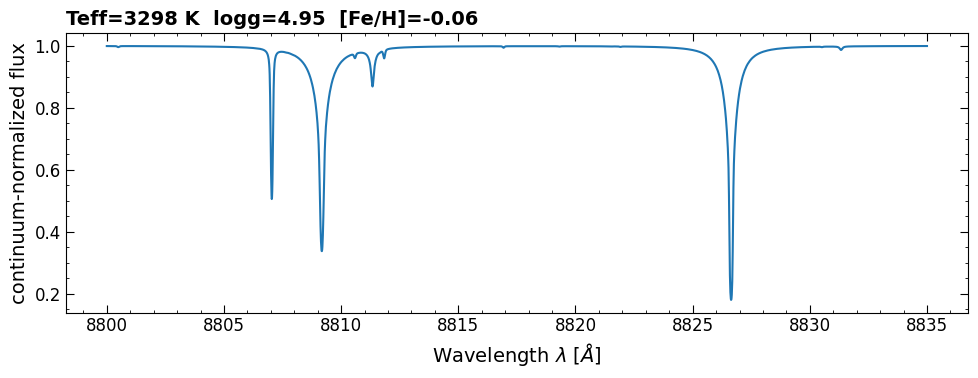

In [15]:
datavis.plot_single_spectrum(df_spectra, row_index=1)
plt.show()

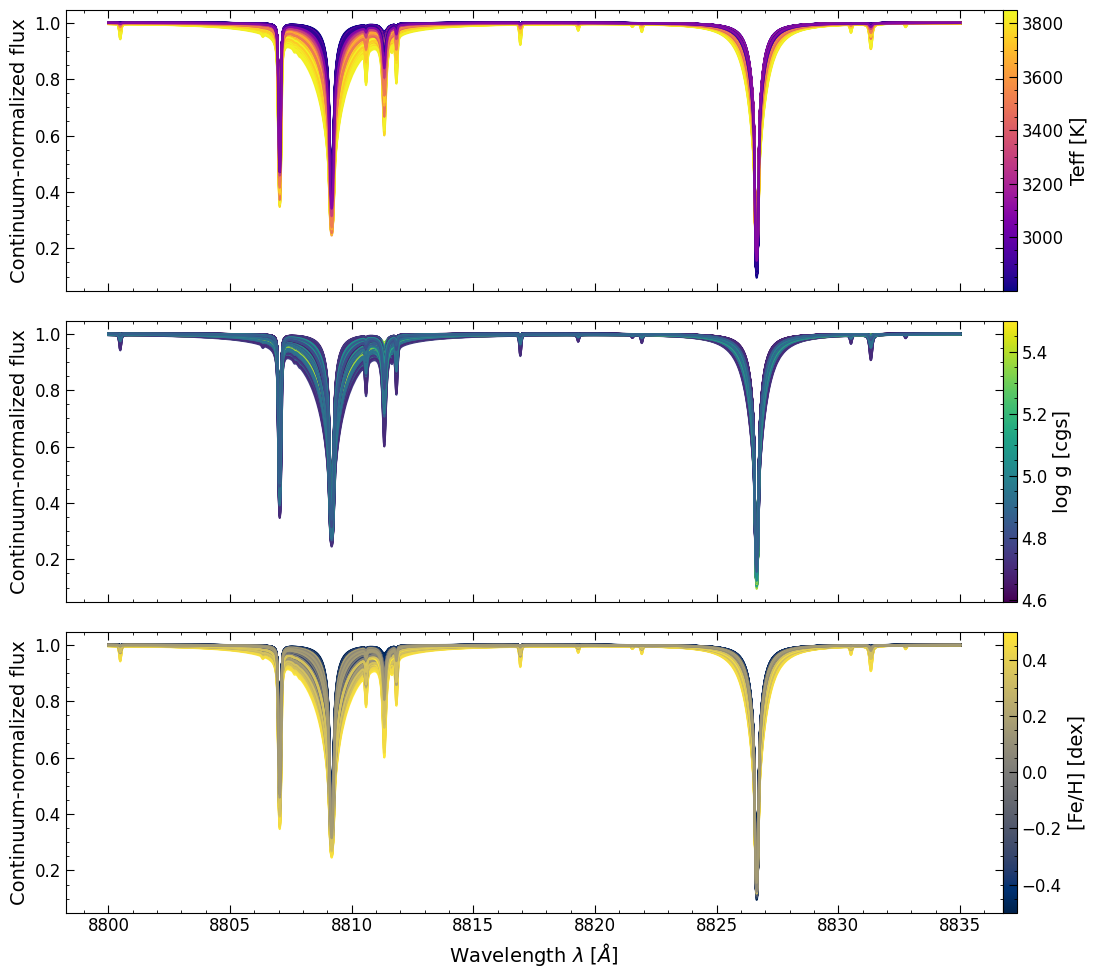

In [16]:
datavis.plot_spectra_colored_by_params(df_spectra)
plt.show()

## Save to Parquet

In [ ]:
# Convert array columns to plain float32 lists for Arrow
df_parquet = df_spectra.copy()
for col in ["wavelength_A", "flux", "continuum"]:
    df_parquet[col] = df_parquet[col].apply(
        lambda x: np.asarray(x, dtype=np.float32).tolist()
    )

BASE_PATH = REPO_ROOT / "data"
BASE_PATH.mkdir(exist_ok=True)

FILENAME = "all_samples.parquet"
full_path = BASE_PATH / FILENAME

# Don't overwrite an existing file, auto-increment the suffix
if full_path.exists():
    counter = 1
    while (BASE_PATH / f"all_samples{counter}.parquet").exists():
        counter += 1
    full_path = BASE_PATH / f"all_samples{counter}.parquet"

df_parquet.to_parquet(full_path, engine="pyarrow", index=False)
print(f"Wrote {full_path}")

Wrote /home/sarah/Documentos/Josue/spectral-windows-for-m-dwarf-host-stars/data/all_samples.parquet


In [20]:
df_check = pd.read_parquet(full_path)
df_check.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3129.031349,4.903465,-0.398154,0.317017,0.329086,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9995366334915161, 0.999535858631134, 0.9995...","[554887.0625, 554887.0, 554886.9375, 554886.87..."
1,3298.260177,4.950254,-0.062917,0.292977,0.299771,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9991995692253113, 0.9991980791091919, 0.999...","[698598.9375, 698598.6875, 698598.4375, 698598..."
2,3366.889872,4.939689,-0.076755,0.310197,0.312230,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9991275668144226, 0.9991258978843689, 0.999...","[747425.6875, 747425.375, 747425.0, 747424.687..."
3,3454.222712,4.928937,-0.050838,0.304602,0.313255,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9989616870880127, 0.9989596605300903, 0.998...","[818224.875, 818224.4375, 818224.0, 818223.562..."
4,3727.077236,4.755964,0.032868,0.477035,0.478402,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.998212456703186, 0.9982085227966309, 0.9982...","[1052843.625, 1052842.75, 1052841.875, 1052841..."


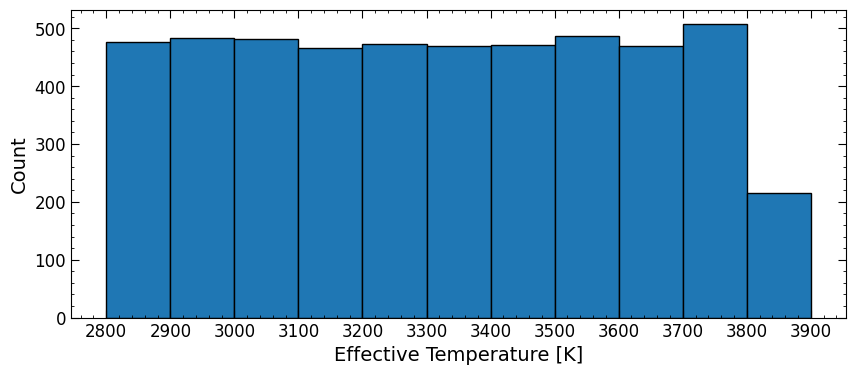

In [27]:
datavis.plot_histogram(
    df_check, "Teff_K", (2800, 3900), 100, xlabel="Effective Temperature [K]"
)
plt.show()

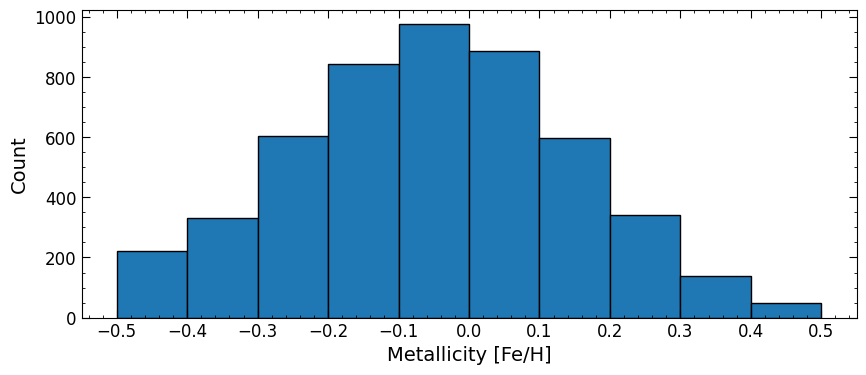

In [28]:
datavis.plot_histogram(
    df_check, "FeH_dex", METALLICITY_FEH_RANGE, 0.1, xlabel="Metallicity [Fe/H]"
)
plt.show()

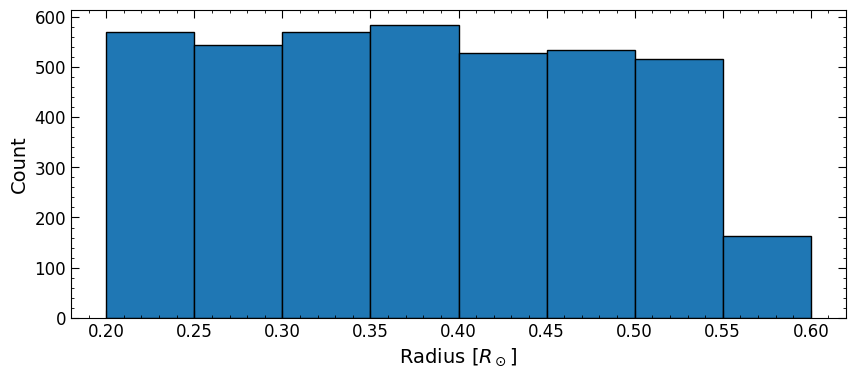

In [29]:
datavis.plot_histogram(
    df_check, "Radius_Rsun", (0.2, 0.6), 0.05, xlabel=r"Radius [$R_\odot$]"
)
plt.show()

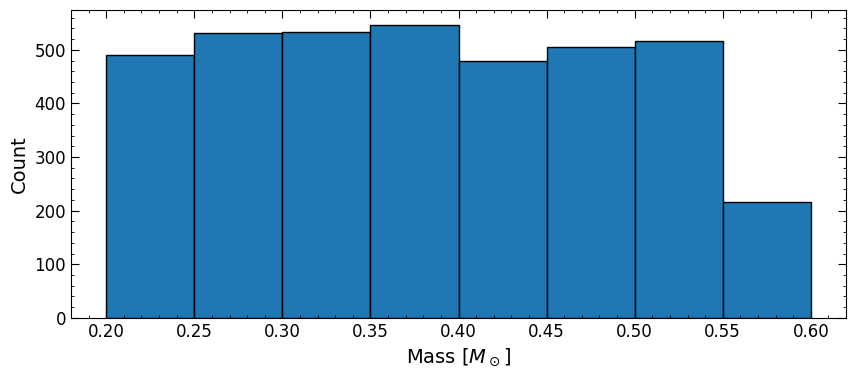

In [30]:
datavis.plot_histogram(
    df_check, "Mass_Msun", (0.2, 0.6), 0.05, xlabel=r"Mass [$M_\odot$]"
)
plt.show()

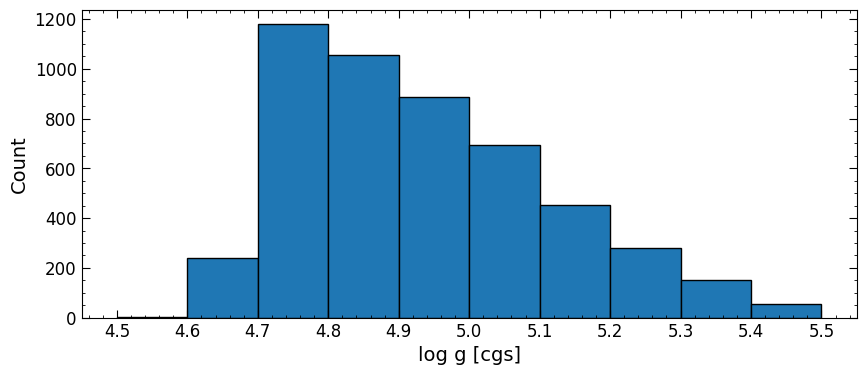

In [35]:
datavis.plot_histogram(df_check, "logg_cgs", (4.5, 5.5), 0.1, xlabel="log g [cgs]")
plt.show()